# Dense Refinement — Qualitative Comparison

Standalone companion to `training_dense_head.ipynb`'s qualitative figure
(the panel comparing the learned dense map against the interpolation
baselines). This notebook does not train anything — it loads a **trained
dense-head checkpoint** and **one NetCDF pass**, then plots the input, the
patch-level ground truth, and every interpolation baseline next to the
learned dense map.

Set the NetCDF file and the two colormaps in the Args cell below.

## Imports & environment

In [10]:
import os
import numpy as np
import torch
import matplotlib.pyplot as plt

from dataio import DataCollatorBlocks, load_nc_item
from inference.inference import load_model
from evaluation.dense_eval import upsample_patch_probs
from evaluation.viz import plot_dense_comparison


def get_device():
    if torch.backends.mps.is_available():
        return torch.device("mps")
    if torch.cuda.is_available():
        return torch.device("cuda")
    return torch.device("cpu")


device = get_device()
print("device:", device)


device: mps


## Args

`block_size` is intentionally not listed here: it is read straight off the
dense checkpoint's stored config in the next cell, so this notebook always
uses whatever block size the head was actually trained with.

In [11]:
from types import SimpleNamespace

args = SimpleNamespace(
    # --- Input pass -----------------------------------------------------
    nc_file="../data/splits/train/SWOT_L3_LR_SSH_Expert_019_161_20240805T121644_20240805T130810_v3.0_labeled.nc",
    channel_vars=["rolling_mean_highpass"],
    mask_var="block_mask",

    # --- Trained dense head ----------------------------------------------
    # A full model checkpoint saved by DenseTrainer (e.g. "best.pt" from
    # training_dense_head.ipynb), not the patch-only detector checkpoint.
    dense_ckpt="../models/dense_head/rolling_mean_highpass_v0.1.0/best.pt",

    # --- Baselines to compare against the learned map ---------------------
    eval_baselines=["nearest", "bilinear", "bicubic", "gaussian"],
    guide_index=-1,          # input channel shown in the "Input" panel

    # --- Figure ------------------------------------------------------------
    input_cmap="gray",       # colormap for the "Input" panel
    map_cmap="jet",      # colormap for ground truth + every dense/interp map
    overlay=False,            # draw interpolation/Learned maps on top of the input
    overlay_alpha=0.55,      # opacity of the confidence map when overlay=True
    layout="auto",           # "auto" | "rows" | "columns", see plot_dense_comparison
    zoom_blocks=6,           # zoom window half-width, in blocks
    save_path=None,          # e.g. "../reports/figures/qualitative_comparison.png"
)
print(args)


namespace(nc_file='../data/splits/train/SWOT_L3_LR_SSH_Expert_019_161_20240805T121644_20240805T130810_v3.0_labeled.nc', channel_vars=['rolling_mean_highpass'], mask_var='block_mask', dense_ckpt='../models/dense_head/rolling_mean_highpass_v0.1.0/best.pt', eval_baselines=['nearest', 'bilinear', 'bicubic', 'gaussian'], guide_index=-1, input_cmap='gray', map_cmap='jet', overlay=False, overlay_alpha=0.55, layout='auto', zoom_blocks=6, save_path=None)


## Load the trained dense head

In [12]:
model, cfg = load_model(args.dense_ckpt, device)
assert cfg.dense_head, (
    f"{args.dense_ckpt} has no dense head attached (dense_head=False in its "
    "stored config); pass a checkpoint saved by DenseTrainer, not the "
    "patch-only detector checkpoint."
)
block_size = cfg.block_size
print(f"Loaded dense head from {args.dense_ckpt}")
print(f"block_size={block_size}  embed_dim={cfg.embed_dim}  depth={cfg.depth}")


Loaded dense head from ../models/dense_head/rolling_mean_highpass_v0.1.0/best.pt
block_size=20  embed_dim=128  depth=64


## Load the NetCDF file into one batch

In [13]:
item = load_nc_item(
    args.nc_file,
    channel_var_names=tuple(args.channel_vars),
    mask_var_name=args.mask_var,
    block_size=block_size,
)

collator = DataCollatorBlocks(
    pad_images=True,
    labels_as_float=True,
    make_block_attention_mask=True,
    flatten_block_attention_mask=False,
    enforce_same_block_size=True,
)
batch = collator([item])

print(f"{item['id']}: image {tuple(batch['images'].shape)}, "
      f"grid {tuple(item['grid_shape'])}, "
      f"{int(item['labels'].sum())} positive blocks")


SWOT_L3_LR_SSH_Expert_019_161_20240805T121644_20240805T130810_v3.0_labeled.nc: image (1, 1, 700, 60), grid (35, 3), 44 positive blocks


## Build every method's dense map

In [14]:
def dense_panels_for_sample(batch, sample_i=0):
    """Build every method's dense map for one sample, plus its inputs."""
    imgs = batch["images"].to(device)
    bm = batch.get("block_attn_mask", batch["valid"]).to(device).bool()

    with torch.no_grad():
        out = model(imgs, block_mask=bm, return_dense=True)

    Bh, Bw = int(out["Bh"]), int(out["Bw"])
    Ht, Wt = Bh * block_size, Bw * block_size

    patch = out["probs"].reshape(imgs.shape[0], Bh, Bw)

    panels = {}
    for mode in args.eval_baselines:
        panels[mode.title()] = upsample_patch_probs(
            patch, block_size, mode)[sample_i, 0].cpu().numpy()
    panels["Learned"] = out["dense_probs"][sample_i, 0].cpu().numpy()

    # Crop label grid to the tokenized region and mask padded blocks.
    labels = batch["labels"][sample_i, :Bh, :Bw].cpu().numpy()
    valid = batch["valid"][sample_i, :Bh, :Bw].cpu().numpy().astype(bool)
    labels = np.where(valid, labels, np.nan)

    image = imgs[sample_i, :, :Ht, :Wt].cpu().numpy()
    ids = batch.get("ids", [f"sample_{sample_i}"])

    return image, labels, panels, str(ids[sample_i])


image, labels, panels, sid = dense_panels_for_sample(batch)
n_pos = int(np.nansum(labels))
print(f"Sample {sid} | {n_pos} positive blocks | image {image.shape}")

if n_pos == 0:
    print("WARNING: no positive blocks in this pass; the confidence panels "
          "will be uniformly low and the figure will not show anything "
          "interesting.")

Ht, Wt = image.shape[-2:]

# Centre the zoom on the densest run of positive blocks so the window lands
# on a signature crossing block boundaries rather than on empty ocean.
lab = np.nan_to_num(labels)
if lab.sum() > 0:
    by_row = lab.sum(axis=1)
    cy = int(np.argmax(np.convolve(by_row, np.ones(3), mode="same"))) * block_size
    cx = int(lab.sum(axis=0).argmax()) * block_size
else:
    cy, cx = Ht // 2, Wt // 2

win = min(args.zoom_blocks * block_size, Ht // 2, Wt // 2)
y0 = int(np.clip(cy - win, 0, max(0, Ht - 2 * win)))
x0 = int(np.clip(cx - win, 0, max(0, Wt - 2 * win)))
zoom = (y0, min(Ht, y0 + 2 * win), x0, min(Wt, x0 + 2 * win))
print(f"zoom window (y0,y1,x0,x1) = {zoom}")


Sample SWOT_L3_LR_SSH_Expert_019_161_20240805T121644_20240805T130810_v3.0_labeled.nc | 44 positive blocks | image (1, 700, 60)
zoom window (y0,y1,x0,x1) = (250, 310, 0, 60)


## Qualitative figure

Input, patch ground truth, and each reconstruction. `input_cmap` colors the
"Input" panel; `map_cmap` colors the ground truth and every interpolation /
learned panel, since they all share the same [0, 1] confidence scale. When
`args.overlay` is True (the default), every interpolation/Learned panel is
drawn as that confidence map layered over the input image at `overlay_alpha`
opacity, instead of on its own.

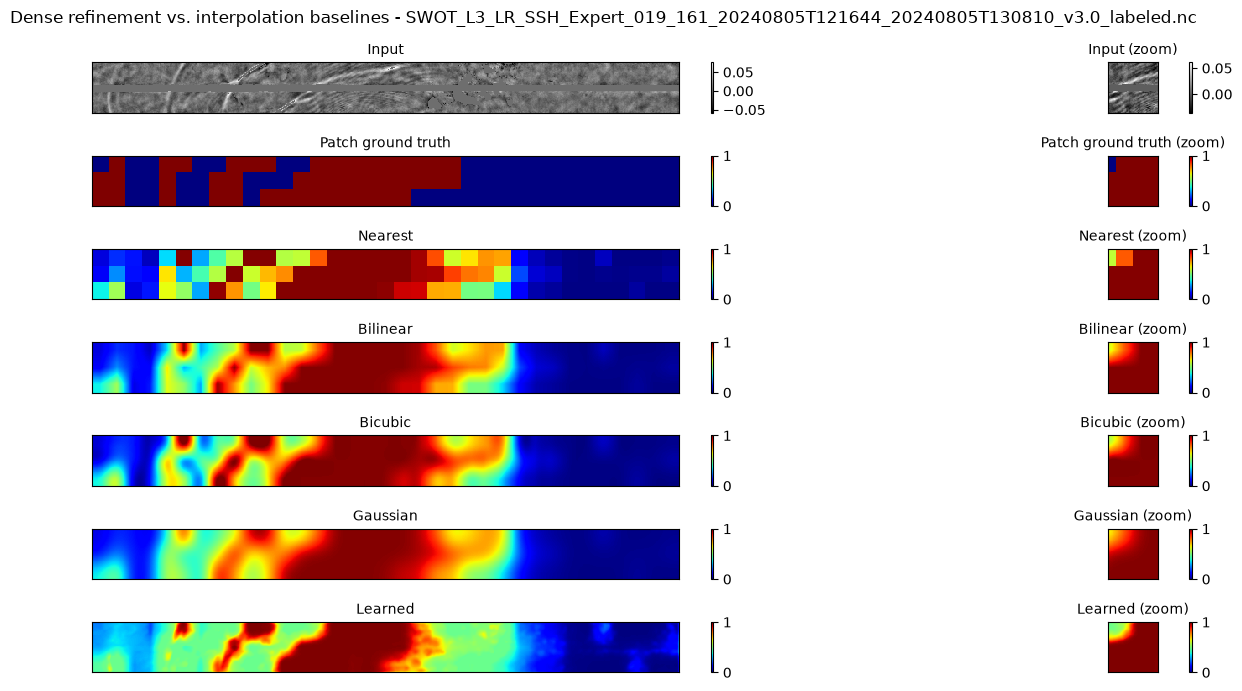

In [15]:
plot_dense_comparison(
    image=image,
    patch_labels=lab,
    dense_by_method=panels,
    block_size=block_size,
    zoom=zoom,
    layout=args.layout,
    guide_index=args.guide_index,
    input_cmap=args.input_cmap,
    map_cmap=args.map_cmap,
    overlay_on_input=args.overlay,
    overlay_alpha=args.overlay_alpha,
    title=f"Dense refinement vs. interpolation baselines - {sid}",
    save_path=args.save_path,
    show=True,
)


## Thresholded segmentation overlay

Same "Learned" dense map as above, but shown as a binary pixel-level
segmentation (`Learned >= seg_threshold`) instead of a continuous heatmap,
drawn directly on top of the full input pass. Pixels belonging to
masked/padded blocks (wherever `labels` is NaN) are left fully transparent,
since there is no ground truth to judge them against.

9569 / 42000 valid pixels segmented as positive at threshold 0.80


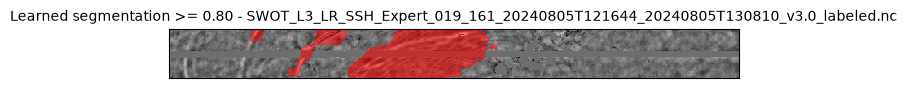

In [16]:
from matplotlib.colors import to_rgba

seg_threshold = 0.8     # probability cutoff for the binary segmentation
seg_color = "red"       # overlay color for pixels >= seg_threshold

learned = panels["Learned"]
valid_px = np.kron(
    ~np.isnan(labels), np.ones((block_size, block_size), dtype=bool)
)
seg_mask = (learned >= seg_threshold) & valid_px

print(f"{seg_mask.sum()} / {valid_px.sum()} valid pixels segmented "
      f"as positive at threshold {seg_threshold:.2f}")

guide = image[args.guide_index]
stack_rows = guide.shape[0] > 2 * guide.shape[1]

overlay = np.zeros((*seg_mask.shape, 4), dtype=np.float32)
overlay[..., :3] = to_rgba(seg_color)[:3]
overlay[..., 3] = np.where(seg_mask, args.overlay_alpha, 0.0)

bg, fg = guide, overlay
if stack_rows:
    bg, fg = bg.T, fg.transpose(1, 0, 2)

fig, ax = plt.subplots(figsize=(6, 10) if stack_rows else (10, 6))
ax.imshow(bg, cmap=args.input_cmap, interpolation="nearest")
ax.imshow(fg, interpolation="nearest")
ax.set_title(f"Learned segmentation >= {seg_threshold:.2f} - {sid}", fontsize=10)
ax.set_xticks([])
ax.set_yticks([])
plt.tight_layout()
plt.show()